# Did Verstappen get Overtake behind Russell in Las Vegas?

The parent project's FIA timing audit found that Max Verstappen crossed the start/finish line first on each of the 18 laps before the Safety Car. This follow-up checks whether George Russell was directly ahead of him by less than 1.0 s at Overtake detection on any of those laps, and whether Verstappen took the lead by the finish. It uses observed race timing and estimates crossings from recorded positions.

Jessica Steele’s analysis of Verstappen and Kimi Antonelli on laps 39–48 prompted the question. Steele aligned lap telemetry with official timing and used the FIA detection location to study where the lead changed. [LinkedIn post](https://lnkd.in/p/esVYKb4W) · [Jessica’s Lap Segmentation Tool](https://f1lapsegmentation-production.up.railway.app/) · [Original strategy notebook](../analysis.ipynb)

## Data and the app check

I generated reports in **Historical → Las Vegas Grand Prix (2026) → Race**, with VER as the reference and RUS as the comparison. The cross-check below compares the displayed replay with the original OpenF1 estimates.

FastF1 3.9.2 resolved the event and race but returned no usable unauthenticated timing, car or position streams. The Formula 1 archive returned HTTP 403 on the direct index request. This run uses **OpenF1 race session 11420** for absolute sample timestamps, XY positions and car speeds. It reuses the parent notebook’s FIA-checked finish timeline and verifies the within-lap splits against the FIA's separate sector report. [FastF1 data reference](https://docs.fastf1.dev/data_reference/index.html) · [OpenF1](https://openf1.org/) · [FIA Race History Chart](https://www.fia.com/sites/default/files/2026_21_usa_f1_r0_timing_racehistorychart_v01.pdf) · [FIA Race Sector Analysis](https://www.fia.com/sites/default/files/2026_21_usa_f1_r0_timing_racesectoranalysis_v01.pdf)

In [1]:
import json
import os
from pathlib import Path

from IPython.display import Image, Markdown, display
import numpy as np
import pandas as pd

from collect import CACHE, HERE, official_timing
from crossings import (
    ACTIVATION_M, DETECTION_M, FIA_KNOTS, PRIMARY, clock_checks,
    difference_bounds, estimate, overtake_messages, summarize_laps,
)

os.environ.setdefault("MPLCONFIGDIR", str(CACHE / "matplotlib"))
os.environ.setdefault("MPLBACKEND", "Agg")
from plotting import gap_figure

timing, race_start = official_timing()
metadata = json.loads((CACHE / "18_inputs.json").read_text())
position = pd.read_csv(CACHE / "18_location.csv.gz")
car_data = pd.read_csv(CACHE / "18_car_data.csv.gz")
print(f"{metadata['source']} | {len(position):,} position samples | {len(car_data):,} car samples")
print(f"{position.car.nunique()} cars with position samples. FIA timing: {len(timing)} completed car-laps.")
print(f"Race clock origin   {race_start.isoformat()}")

OpenF1 | 144,379 position samples | 141,339 car samples
21 cars with position samples. FIA timing: 377 completed car-laps.
Race clock origin   2026-11-22T04:03:46.118000+00:00


## Lap 2 pilot

All signed VER–RUS gaps in this project are **Russell crossing time minus Verstappen crossing time**. Positive means Verstappen crossed first. The previous FIA finish supplies the lap 2 starting gap. Russell’s 1:39.862 versus Verstappen’s 1:39.965 gives a lap-time delta of −0.103 s, so **+0.276 − 0.103 = +0.173 s** at the finish. The split times add checks inside the lap.

In [2]:
lap2 = timing.loc[timing.lap.eq(2)].set_index("driver")
rus, ver = lap2.loc["RUS"], lap2.loc["VER"]
start_gap = rus.start_s - ver.start_s
lap_delta = rus.lap_time_s - ver.lap_time_s
finish_gap = rus.finish_s - ver.finish_s
assert np.allclose([start_gap, lap_delta, finish_gap], [0.276, -0.103, 0.173], atol=0.001)
assert np.isclose(start_gap + lap_delta, finish_gap, atol=0.001)
print(f"{start_gap:+.3f} s at start + ({lap_delta:+.3f} s lap-time delta) = {finish_gap:+.3f} s at finish")
display(lap2.loc[["VER", "RUS", "HAD"],
                ["lap_time_s", "s1_s", "s2_s", "s3_s", "fia_history_gap_s"]].round(3))

+0.276 s at start + (-0.103 s lap-time delta) = +0.173 s at finish


,lap_time_s,s1_s,s2_s,s3_s,fia_history_gap_s
driver,,,,,
VER,99.965,29.167,33.711,37.087,0.000
RUS,99.862,29.446,34.033,36.383,0.173
HAD,99.546,29.142,34.139,36.265,0.644


### One position axis for both cars

The FIA lists the detection loop **L19 at 5,299 m** and activation loop **L20 at 5,400 m** on a 6,201 m centreline. These are loop identifiers. The circuit map puts S1 after Turn 5, S2 after Turn 12, and detection in the Turn 16 exit area with activation downstream toward Turn 17 and the control line. Its sector lengths put S1 at 1,693 m and S2 at 3,428 m. The numeric gate distances come from Power Unit Information.

I measured the arc length along Verstappen’s lap 2 XY trace between successive FIA control crossings. The relative UTC clock is shared across the field. I mapped the FIA distances to this trace with the three sector lengths, then drew a line perpendicular to the reference path at each gate. The mapped marks lie around the final kink onto the run toward the control line, after the Turn 14 braking complex. Each driver’s actual samples straddling the same gate give the crossing time by interpolation. I checked the circuit-map ordering and that the trace closes at its start/finish point. The map supports the landmark check. The crossing estimate still depends on the distance map.

The app reports a 6,157 m axis. Uniform whole-lap scaling would put detection near 5,261 m and activation near 5,362 m on that axis. Interpolating in the app’s final sector using its reported S2 and finish positions puts detection near 5,260 m. [FIA Power Unit Information](https://www.fia.com/system/files/decision-document/2026_las_vegas_grand_prix_-_power_unit_information.pdf) · [FIA circuit map, page 2](https://www.fia.com/system/files/decision-document/2026_las_vegas_grand_prix_-_competition_notes_-_circuit_map_pit_lane_drawing_emergency_exits_map_and_red_zone.pdf#page=2)

In [3]:
pilot, pilot_courses, variants = estimate(timing, position, car_data, max_lap=2)
axis = pilot_courses["VER"]
marks = np.array([0, FIA_KNOTS[1], FIA_KNOTS[2], DETECTION_M, ACTIVATION_M, FIA_KNOTS[3]])
mapped_positions = axis.from_fia(marks)
landmarks = pd.DataFrame({
    "FIA centreline m": marks,
    "VER lap 2 position axis m": mapped_positions,
    "X m": axis.point(mapped_positions)[:, 0],
    "Y m": axis.point(mapped_positions)[:, 1],
}, index=["Control line (start)", "Sector 1", "Sector 2", "Detection", "Activation", "Control line (finish)"])
display(landmarks.round(1))
print(f"Control line XY closure: {np.linalg.norm(axis.xy[0] - axis.xy[-1]):.2f} m")

,FIA centreline m,VER lap 2 position axis m,X m,Y m
Control line (start),0.0,0.0,186.9,-85.2
Sector 1,1693.0,1688.3,145.6,1071.2
Sector 2,3428.0,3425.7,-545.2,1606.7
Detection,5299.0,5282.1,-680.9,-154.5
Activation,5400.0,5382.3,-584.4,-171.9
Control line (finish),6201.0,6177.1,187.2,-84.8


Control line XY closure: 0.45 m


### Compare with the FIA clock

Raw UTC crossing estimates use the same sample clock. The main estimate also pins each driver’s sector-three transit to their FIA **S2 and finish times** with a linear correction between those two gates. A pit-lane finish or an unresolvable anchor leaves the raw clock for that car. Comparing the raw gap at S1, S2 and the finish with the FIA gap tests the alignment before any correction.

In [4]:
pilot_checks = clock_checks(pilot)
display(pilot_checks.loc[pilot_checks.lap.eq(2) & pilot_checks.driver.eq("RUS")]
        .set_index("landmark")[["fia_gap_s", "raw_gap_s", "error_s"]].round(3))

pilot_field = pilot.loc[pilot.lap.eq(2) & pilot.driver.isin(["RUS", "VER", "HAD"])].set_index("driver")
pilot_ver = pilot_field.loc["VER"]
display(pd.DataFrame({
    "Raw detection gap to VER (s)": pilot_field["shared UTC"] - pilot_ver["shared UTC"],
    "Aligned detection gap to VER (s)": pilot_field[PRIMARY] - pilot_ver[PRIMARY],
    "Aligned activation gap to VER (s)": pilot_field.activation_s - pilot_ver.activation_s,
    "FIA finish gap to VER (s)": pilot_field.finish_s - pilot_ver.finish_s,
}).sort_values("Aligned detection gap to VER (s)").round(3))

speed_gap = pilot_field.loc["RUS", "speed_inferred_crossing_s"] - pilot_ver["speed_inferred_crossing_s"]
display(pilot_field[["speed_inferred_gate_error_m"]].round(1))
print(f"If each speed trace is integrated and scaled separately, the implied lap 2 gap is {speed_gap:+.3f} s.")

,fia_gap_s,raw_gap_s,error_s
landmark,,,
S1,0.555,0.607,0.052
S2,0.877,0.882,0.005
Finish,0.173,0.116,-0.057


,Raw detection gap to VER (s),Aligned detection gap to VER (s),Aligned activation gap to VER (s),FIA finish gap to VER (s)
driver,,,,
RUS,-0.538,-0.502,-0.679,0.173
VER,0.000,0.000,0.000,0.000
HAD,0.464,0.571,0.335,0.644


,speed_inferred_gate_error_m
driver,
VER,-33.3
HAD,-20.5
RUS,-7.0


If each speed trace is integrated and scaled separately, the implied lap 2 gap is +0.271 s.


The shared-line estimate has Russell about **0.50 s ahead** at detection, with Hadjar about **0.57 s behind** Verstappen. Verstappen finished the lap **0.173 s ahead** of Russell. Formula 1’s report describes Russell taking the lead on lap 2 and Verstappen getting back in front at the final corner. [Formula 1 race report](https://www.formula1.com/en/latest/article/verstappen-wins-exhilarating-las-vegas-grand-prix-from-norris-and-piastri.2eeBWqekZdir9mdDVK9YVX)

As a diagnostic I also integrated car speed between the S2 and finish anchors. On lap 2 the independently scaled distances place Verstappen about 33 m upstream of the common gate at his inferred crossing time, and Russell about 7 m upstream. That mismatch is enough to reverse the inferred order. It demonstrates why the order check moves the same physical line for every car. The sensitivity runs use shared position gates.

## Overtake availability and the full field

Under **B7.2.2(b)**, the leader’s first detection crossing after the standing start enables Overtake. The race-control feed logs the enable message on lap 1 at 04:04:55 UTC and disable on lap 19 at 04:34:26 UTC, corroborated to the minute by the FIA report. The lead car's estimated first detection crossing comes later than the lap 1 message. The public timestamp supplies the lap of the enable message. The regulation supplies the actual first-detection trigger. On laps 2–18 the published state is enabled throughout the leaders’ passages.

Under **B7.2.3(c)**, a car less than **1.0 s** behind another car at detection can qualify for activation at the separate activation line. I check the immediately preceding car from the physical crossings, including nearby passages by cars on different lap numbers. The detection leader is the first car through on the race lap. The FIA control line supplies the finish leader. The estimates describe order and gap-based eligibility. Public car speed and XY leave control-electronics notifications, deployment and driver intent unobserved.

The sensitivity range varies the FIA detection location by ±40 m in 5 m steps, checks a uniform scale and the same distance remaining to the finish, uses Russell’s lap 2 position trace as a second reference, and compares the raw UTC clock. The envelope of each pair’s gaps gets a margin from the 95th percentile absolute VER–RUS and VER–HAD raw gap error at the FIA sector splits and finish, with a floor of 0.05 s. The resulting whiskers describe sensitivity to these choices. The scan flags margins that cross a tie or the 1.0 s threshold. Two field crossings lack precise interpolations. Their position brackets or FIA S2 times place those cars outside the fight at detection.

[FIA Sporting Regulations Issue 09, B7.2.2–3](https://www.fia.com/system/files/documents/fia_2026_f1_regulations_-_section_b_sporting_-_iss_09_-_2026-10-01.pdf#page=65) · [FIA Race Control Messages](https://www.fia.com/sites/default/files/2026_21_usa_f1_r0_timing_raceracecontrolmessages_v01.pdf)

In [5]:
messages = overtake_messages(race_start)
display(messages.loc[messages.lap.le(19), ["lap", "utc", "message"]].reset_index(drop=True))

estimates, courses, variants = estimate(timing, position, car_data)
checks = clock_checks(estimates)
result, clock_pad = summarize_laps(estimates, variants, messages)
assert result.lap.to_list() == list(range(1, 19))
assert result.finish_leader.eq("VER").all()
assert np.isclose(result.loc[result.lap.eq(18), "finish_rus_minus_ver_s"].item(), 0.007, atol=0.001)
assert result.loc[result.pattern.eq("yes"), "rus_directly_ahead_of_ver"].eq("yes").all()

print(f"Clock margin {clock_pad:.3f} s from {checks.error_s.notna().sum()} valid gap checks.")
display(result[["lap", "detection_leader", "detection_rus_minus_ver_s", "detection_gap_low_s",
                "detection_gap_high_s", "ver_car_ahead_at_detection", "finish_leader",
                "finish_rus_minus_ver_s", "overtake_eligibility", "pattern"]].round(3))

,lap,utc,message
0,1,2026-11-22 03:57:03+00:00,OVERTAKE DISABLED
1,1,2026-11-22 04:04:55+00:00,OVERTAKE ENABLED
2,19,2026-11-22 04:34:26+00:00,SAFETY CAR DEPLOYED
3,19,2026-11-22 04:34:26+00:00,OVERTAKE DISABLED


Clock margin 0.145 s from 106 valid gap checks.


,lap,detection_leader,detection_rus_minus_ver_s,detection_gap_low_s,detection_gap_high_s,ver_car_ahead_at_detection,finish_leader,finish_rus_minus_ver_s,overtake_eligibility,pattern
0,1,VER,1.340,1.072,1.680,,VER,0.276,no,no
1,2,RUS,-0.502,-0.800,-0.222,RUS,VER,0.173,estimated yes,yes
2,3,VER,0.566,0.307,0.783,,VER,0.794,no,no
3,4,VER,0.503,0.133,0.684,,VER,0.949,no,no
4,5,VER,0.940,0.668,1.139,,VER,0.796,no,no
5,6,VER,0.327,0.102,0.706,,VER,0.429,no,no
6,7,VER,0.800,0.636,1.111,,VER,0.749,no,no
7,8,VER,0.665,0.469,0.934,,VER,0.392,uncertain,no
8,9,VER,0.466,0.125,0.611,,VER,0.181,no,no
9,10,RUS,-0.253,-0.574,-0.022,RUS,VER,0.202,estimated yes,yes


In [6]:
matches = result.loc[result.pattern.eq("yes")]
count = result.pattern.isin(["yes", "no"]).sum()
match_laps = ", ".join(matches.lap.astype(str))
display(Markdown(f"**OpenF1 classifies {count}/18 laps under its timing and location checks.** "
                 f"OpenF1 candidates on laps **{match_laps}**."))
display(matches[["lap", "ver_gap_to_car_ahead_s", "activation_rus_minus_ver_s",
                 "finish_rus_minus_ver_s"]].round(3).set_index("lap"))
display(result.loc[result.uncertainty_notes.ne(""), ["lap", "uncertainty_notes"]].set_index("lap"))

lap10 = estimates.loc[estimates.lap.eq(10)].set_index("driver")
largest_error = checks.error_s.abs().max()
print("Lap 10 stress using the largest observed split/finish gap error "
      f"({largest_error:.3f} s) as the clock margin:",
      tuple(round(x, 3) for x in difference_bounds(lap10.loc["RUS"], lap10.loc["VER"], variants, largest_error)))

**OpenF1 classifies 18/18 laps under its timing and location checks.** OpenF1 candidates on laps **2, 10, 14, 18**.

,ver_gap_to_car_ahead_s,activation_rus_minus_ver_s,finish_rus_minus_ver_s
lap,,,
2,0.502,-0.679,0.173
10,0.253,-0.231,0.202
14,0.376,-0.404,0.136
18,0.409,-0.431,0.007


,uncertainty_notes
lap,
1,Standing start. First leader detection enables...
8,VER eligibility varies with the preceding-car ...
10,Small margin to a tie after the location and t...
15,No precise crossing for COL well behind the le...
16,Shared UTC used for at least one of VER or RUS
18,No precise crossing for CAM well behind the le...


Lap 10 stress using the largest observed split/finish gap error (0.189 s) as the clock margin: (np.float64(-0.617), np.float64(0.021))


**Reading the close calls.** Lap 10 is the weakest match. The OpenF1-only call clears the timing margin used here. Using the largest observed timing error as the margin would leave it uncertain in that model. On lap 8, Hadjar could have been level with or ahead of Verstappen within the sensitivity band. Russell was behind Verstappen across the same checks, so lap 8 fails the Russell-specific test either way. Lap 1 also fails that test, with Verstappen first at detection.

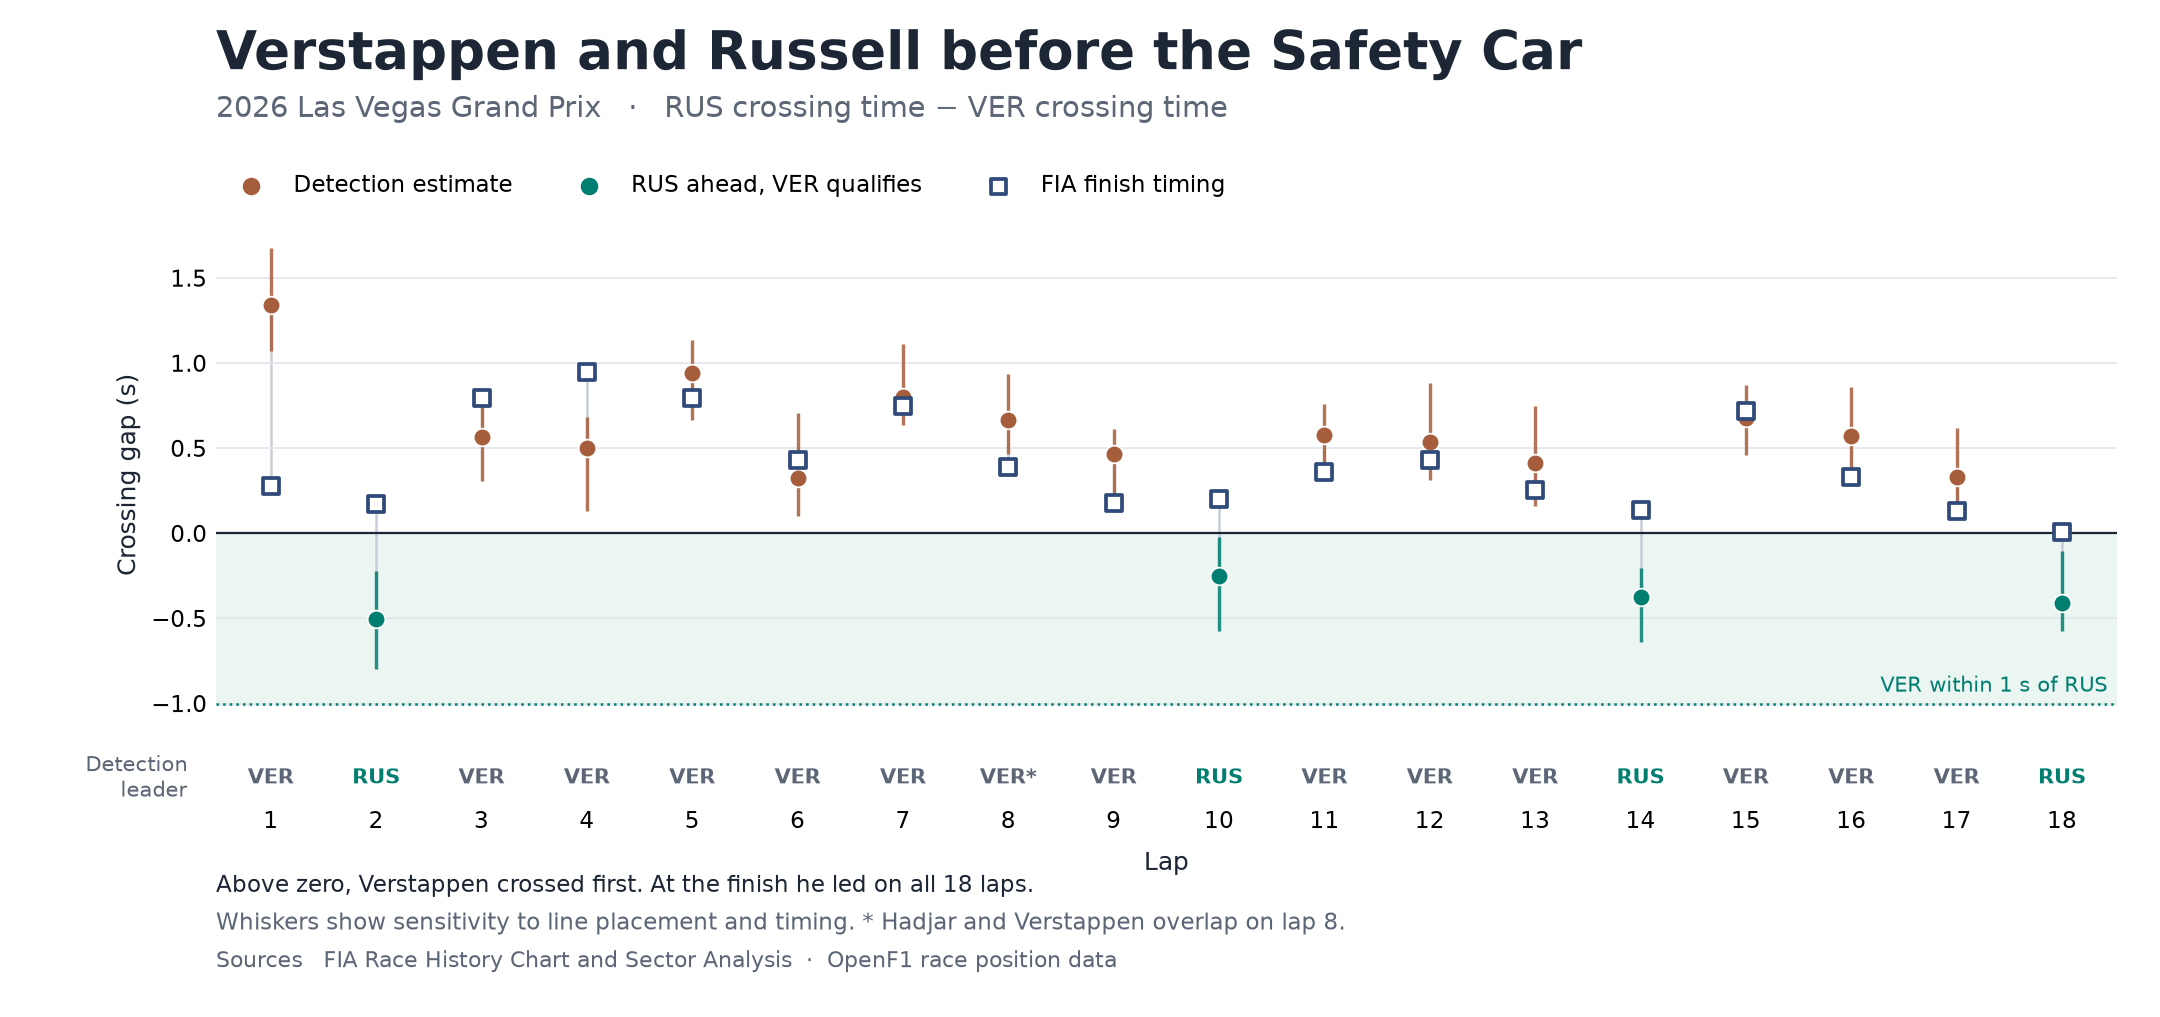

In [7]:
csv_path = HERE / "lap_by_lap.csv"
figure_path = HERE / "detection_vs_finish.png"
result.to_csv(csv_path, index=False, float_format="%.3f")
gap_figure(result, metadata["source"], figure_path)
display(Image(filename=str(figure_path), width=960))

The green markers show the four OpenF1 candidates where Russell crossed detection first, Verstappen was within the gap threshold, and the FIA recorded Verstappen first at the finish. The sensitivity whiskers belong to the detection estimates. See the [CSV](lap_by_lap.csv) for the activation gaps, the car ahead of Verstappen, the race-control status and the reason for any uncertain call.

## Cross-check against Jessica Steele’s replay

I verified the **Las Vegas Grand Prix 2026 Race** header and the selected lap in both driver fields for each report. The recorded replay readings below make the check repeatable offline. To put the two axes on the same stretch, map the FIA final sector (3,428–6,201 m) onto each report’s S2 and finish distances. The FIA detection line is at 5,299 m, which the OpenF1 geometry maps to 5,282 m. I checked the app’s T16 and T17 labels against the final kink and straight in the FIA map and the OpenF1 trace. This locates the stretch of track to compare. A displayed metre and delta in the app provide an approximate crossing estimate.

The app starts the two laps together, so add the official opening gap to its RUS-minus-VER delta. OpenF1 uses a common session clock and the FIA sector-three anchors. **Negative values mean Russell crossed first.** The paired replay checks order and gap. The OpenF1 field checks for another car between them. [Lap Segmentation Tool](https://f1lapsegmentation-production.up.railway.app/) · [FIA timing and circuit information](https://www.fia.com/events/fia-formula-one-world-championship/season-2026/las-vegas-grand-prix/eventtiming-information)

In [8]:
from crossings import align_to_s3, cross_gate

# Reports and replay readings transcribed from the tool, with lap-relative deltas.
reports = pd.DataFrame([(2, 3400.1, 6156, 99.965, 99.862, -0.103, 0.683, -0.108),
 (10, 3397.1, 6152, 98.725, 98.74600000000001, 0.021, 0.709, 0.022),
 (14, 3388.3, 6152, 98.269, 98.149, -0.12, 0.839, -0.119),
 (18,
  3387.9,
  6157,
  97.93299999999999,
  97.80799999999999,
  -0.125,
  0.958,
  -0.125)], columns=[
    "lap", "s2_m", "line_m", "ver_lap_s", "rus_lap_s", "official_delta_s",
    "raw_s2_delta_s", "raw_line_delta_s",
]).set_index("lap")
app_samples = pd.DataFrame([(2, -40, 5220, -0.293, 'approaching T16'),
 (2, 0, 5260, -0.401, 'approaching T16'),
 (2, 40, 5299, -0.467, 'approaching T17'),
 (10, -80, 5176, -0.393, 'approaching T15'),
 (10, -60, 5196, -0.442, 'approaching T15'),
 (10, -40, 5216, -0.457, 'approaching T16'),
 (10, -20, 5236, -0.465, 'approaching T16'),
 (10, 0, 5256, -0.479, 'approaching T16'),
 (10, 20, 5276, -0.477, 'approaching T17'),
 (10, 40, 5296, -0.484, 'approaching T17'),
 (10, 60, 5315, -0.488, 'approaching T17'),
 (10, 80, 5335, -0.487, 'approaching T17'),
 (10, 300, 5554, -0.388, 'approaching T17'),
 (10, 400, 5653, -0.291, 'approaching T17'),
 (10, 500, 5753, -0.191, 'approaching T17'),
 (10, 902, 6152, 0.021, 'approaching T1'),
 (10, 509, 5762, -0.182, 'approaching T17'),
 (10, 512, 5765, -0.18, 'approaching T17'),
 (14, -80, 5173, -0.488, 'approaching T15'),
 (14, -60, 5193, -0.543, 'approaching T15'),
 (14, -40, 5213, -0.541, 'approaching T16'),
 (14, -30, 5223, -0.542, 'approaching T16'),
 (14, -20, 5233, -0.545, 'approaching T16'),
 (14, -10, 5243, -0.545, 'approaching T16'),
 (14, 0, 5253, -0.542, 'approaching T16'),
 (14, 10, 5263, -0.54, 'approaching T16'),
 (14, 20, 5273, -0.541, 'approaching T17'),
 (14, 30, 5283, -0.543, 'approaching T17'),
 (14, 40, 5293, -0.547, 'approaching T17'),
 (14, 60, 5313, -0.554, 'approaching T17'),
 (14, 80, 5333, -0.556, 'approaching T17'),
 (14, 902, 6152, -0.12, 'approaching T1'),
 (18, -80, 5176, -0.399, 'approaching T15'),
 (18, -60, 5196, -0.416, 'approaching T15'),
 (18, -40, 5216, -0.443, 'approaching T16'),
 (18, -20, 5236, -0.467, 'approaching T16'),
 (18, 0, 5256, -0.473, 'approaching T16'),
 (18, 20, 5276, -0.481, 'approaching T17'),
 (18, 40, 5296, -0.489, 'approaching T17'),
 (18, 60, 5316, -0.499, 'approaching T17'),
 (18, 80, 5336, -0.502, 'approaching T17'),
 (18, 300, 5556, -0.457, 'approaching T17'),
 (18, 400, 5656, -0.416, 'approaching T17'),
 (18, 500, 5756, -0.37, 'approaching T17'),
 (18, 902, 6157, -0.125, 'approaching T1'),
 (18, 884, 6139, -0.134, 'approaching T1'),
 (18, 888, 6143, -0.132, 'approaching T1')], columns=[
    "lap", "offset_m", "app_m", "lap_delta_s", "app_landmark",
]).drop_duplicates(["lap", "offset_m"])
fraction = (DETECTION_M + app_samples.offset_m - FIA_KNOTS[2]) / (FIA_KNOTS[-1] - FIA_KNOTS[2])
axis_s2 = app_samples.lap.map(reports.s2_m)
axis_finish = app_samples.lap.map(reports.line_m)
np.testing.assert_allclose(app_samples.app_m, axis_s2 + fraction * (axis_finish - axis_s2),
                           rtol=0, atol=1.5)
review_laps = [2, 10, 14, 18]
pair = estimates.loc[estimates.lap.isin(review_laps) & estimates.driver.isin(["RUS", "VER"])]
ver = pair.loc[pair.driver.eq("VER")].set_index("lap")
rus = pair.loc[pair.driver.eq("RUS")].set_index("lap")
opening = (rus.start_s - ver.start_s).round(3)
official_finish = (rus.finish_s - ver.finish_s).round(3)
np.testing.assert_allclose(opening + rus.lap_time_s - ver.lap_time_s, official_finish, atol=0.001)
np.testing.assert_allclose(reports.ver_lap_s, ver.loc[reports.index, "lap_time_s"], atol=0.001)
np.testing.assert_allclose(reports.rus_lap_s, rus.loc[reports.index, "lap_time_s"], atol=0.001)
np.testing.assert_allclose(opening.loc[reports.index] + reports.official_delta_s,
                           official_finish.loc[reports.index], atol=0.001)
app_samples["race_gap_s"] = (app_samples.lap.map(opening) + app_samples.lap_delta_s).round(3)

# Reuse the reference geometry and the existing S2/finish clock anchors.
def local_openf1(lap, offset):
    course = courses["VER"]
    distance = course.from_fia(DETECTION_M + offset)
    remaining_s = course.time[-1] - np.interp(distance, course.distance, course.time)
    times = []
    for car in (ver.loc[lap], rus.loc[lap]):
        samples = position.loc[position.car.eq(car.driver_number)]
        raw, _, _ = cross_gate(course, distance, samples, car.finish_s - remaining_s, 6)
        times.append(align_to_s3(raw, car.raw_s2_s, car.raw_finish_s, car))
    return times[1] - times[0]

offsets = [-80, -40, -20, 0, 20, 40, 80]
openf1_samples = pd.DataFrame(
    [(lap, offset, local_openf1(lap, offset)) for lap in review_laps for offset in offsets],
    columns=["lap", "offset_m", "openf1_gap_s"],
)
main = result.set_index("lap").loc[review_laps]
openf1_marker = openf1_samples.loc[openf1_samples.offset_m.eq(0)].set_index("lap").openf1_gap_s
np.testing.assert_allclose(openf1_marker, main.detection_rus_minus_ver_s, atol=0.000001)
app_marker = app_samples.loc[app_samples.offset_m.eq(0)].set_index("lap").race_gap_s.reindex(review_laps)
order = pd.Series("OpenF1 only", index=review_laps)
for lap in app_marker.dropna().index:
    method_agreement = (
        -1 < app_marker[lap] < 0
        and app_samples.loc[app_samples.lap.eq(lap) & app_samples.offset_m.abs().le(40),
                            "race_gap_s"].between(-1, 0, inclusive="neither").all()
        and openf1_samples.loc[openf1_samples.lap.eq(lap) & openf1_samples.offset_m.abs().le(40),
                               "openf1_gap_s"].between(-1, 0, inclusive="neither").all()
        and main.loc[lap, "rus_directly_ahead_of_ver"] == "yes"
    )
    order.loc[lap] = "Both support RUS ahead" if method_agreement else "Uncertain"
comparison = pd.DataFrame({
    "Steele replay, approximate (s)": app_marker,
    "OpenF1 estimate (s)": openf1_marker,
    "FIA finish gap (s)": official_finish,
    "Detection order": order,
})
display(comparison.round(3).rename_axis("Lap"))

,"Steele replay, approximate (s)",OpenF1 estimate (s),FIA finish gap (s),Detection order
Lap,,,,
2,-0.125,-0.502,0.173,Both support RUS ahead
10,-0.298,-0.253,0.202,Both support RUS ahead
14,-0.286,-0.376,0.136,Both support RUS ahead
18,-0.341,-0.409,0.007,Both support RUS ahead


In [9]:
# The local readings move the detection mark by the same FIA distances.
side_by_side = openf1_samples.merge(
    app_samples[["lap", "offset_m", "app_m", "race_gap_s", "app_landmark"]],
    on=["lap", "offset_m"], how="left",
)
display(side_by_side.set_index(["lap", "offset_m"]).round(3))

# Check the actual field on each race lap. The main scan also checks lapped traffic.
front = estimates.loc[estimates.lap.isin(review_laps)].sort_values(["lap", PRIMARY]).groupby("lap").head(3).copy()
front["gap_to_ver_s"] = front[PRIMARY] - front.lap.map(ver[PRIMARY])
display(front.set_index(["lap", "driver"])[["gap_to_ver_s"]].round(3))

# Look downstream at the first large change in the projected lead.
downstream = pd.DataFrame(
    [(lap, offset, local_openf1(lap, offset)) for lap in [10, 18] for offset in [300, 400, 500]],
    columns=["lap", "offset_m", "openf1_gap_s"],
)
downstream = downstream.merge(app_samples[["lap", "offset_m", "race_gap_s"]],
                              on=["lap", "offset_m"])
display(downstream.set_index(["lap", "offset_m"]).round(3))

# Probe the rejected gate on the raw position trace.
course = courses["VER"]
gate = course.from_fia(DETECTION_M + 400)
origin, direction = course.point(gate), course.direction(gate)
remaining_s = course.time[-1] - np.interp(gate, course.distance, course.time)
for lap in [10, 18]:
    car = rus.loc[lap]
    eta = car.finish_s - remaining_s
    xy = position.loc[position.car.eq(car.driver_number) & position.t_s.between(eta - 6, eta + 6),
                      ["x", "y"]].to_numpy()
    along = (xy - origin) @ direction
    forward = ((along[:-1] <= 0) & (along[1:] > 0)).sum()
    print(f"Lap {lap}, RUS at detection +400 m: {forward} forward crossings on the raw trace.")

display(app_samples.loc[app_samples.offset_m.between(501, 901),
                        ["lap", "offset_m", "app_m", "race_gap_s"]].set_index("lap"))

openf1_gap_s   app_m  race_gap_s     app_landmark
lap offset_m                                                   
2   -80             -0.353     NaN         NaN              NaN
    -40             -0.390  5220.0      -0.017  approaching T16
    -20             -0.441     NaN         NaN              NaN
     0              -0.502  5260.0      -0.125  approaching T16
     20             -0.430     NaN         NaN              NaN
     40             -0.655  5299.0      -0.191  approaching T17
     80             -0.574     NaN         NaN              NaN
10  -80             -0.320  5176.0      -0.212  approaching T15
    -40             -0.265  5216.0      -0.276  approaching T16
    -20             -0.399  5236.0      -0.284  approaching T16
     0              -0.253  5256.0      -0.298  approaching T16
     20             -0.384  5276.0      -0.296  approaching T17
     40             -0.269  5296.0      -0.303  approaching T17
     80             -0.270  5335.0      -0.306  approaching T17
14  -80             -0.338  5173.0      -0.232  approaching T15
    -40             -0.435  5213.0      -0.285  approaching T16
    -20             -0.377  5233.0      -0.289  approaching T16
     0              -0.376  5253.0      -0.286  approaching T16
     20             -0.369  5273.0      -0.285  approaching T17
     40             -0.349  5293.0      -0.291  approaching T17
     80             -0.332  5333.0      -0.300  approaching T17
18  -80             -0.259  5176.0      -0.267  approaching T15
    -40             -0.338  5216.0      -0.311  approaching T16
    -20             -0.261  5236.0      -0.335  approaching T16
     0              -0.409  5256.0      -0.341  approaching T16
     20             -0.293  5276.0      -0.349  approaching T17
     40             -0.345  5296.0      -0.357  approaching T17
     80             -0.192  5336.0      -0.370  approaching T17

gap_to_ver_s
lap driver              
2   RUS           -0.502
    VER            0.000
    HAD            0.571
10  RUS           -0.253
    VER            0.000
    GAS            0.910
14  RUS           -0.376
    VER            0.000
    HAD            0.786
18  RUS           -0.409
    VER            0.000
    HAD            0.458

openf1_gap_s  race_gap_s
lap offset_m                          
10  300             -0.153      -0.207
    400                NaN      -0.110
    500              0.694      -0.010
18  300             -0.326      -0.325
    400                NaN      -0.284
    500              0.541      -0.238

Lap 10, RUS at detection +400 m: 2 forward crossings on the raw trace.
Lap 18, RUS at detection +400 m: 2 forward crossings on the raw trace.


,offset_m,app_m,race_gap_s
lap,,,
10,509,5762,-0.001
10,512,5765,0.001
18,884,6139,-0.002
18,888,6143,0.000


**Lap 10 stays in the findings.** The replay gives +0.181 − 0.479 = **−0.298 s** at the mapped marker. OpenF1 gives **−0.253 s**. The selected samples through ±80 m keep Russell ahead and Verstappen within a second in both methods. Gasly is the closest third car at the OpenF1 marker, about 0.91 s behind Verstappen. The official lap-time delta was +0.021 s, giving **+0.202 s** at the finish. The replay shows Verstappen getting back ahead roughly 510 m downstream of detection.

**Lap 14 shows the same order.** The app's S2 at 3,388.3 m and finish at 6,152 m put detection near 5,253 m. Adding the +0.256 s opening gap to the replay's −0.542 s lap-relative delta gives **−0.286 s**, alongside OpenF1's **−0.376 s**. Across the tested ±40 m shifts, the replay puts Russell about 0.28–0.29 s ahead and OpenF1 about 0.35–0.50 s ahead. Hadjar is next after Verstappen in the OpenF1 field, about 0.79 s back. The lap times of 1:38.269 for Verstappen and 1:38.149 for Russell reconcile to **+0.136 s** in Verstappen's favour at the FIA finish.

**Lap 18 also holds up.** The replay gives +0.132 − 0.473 = **−0.341 s** at the mapped marker. OpenF1 gives **−0.409 s**. The selected samples through ±80 m keep the order and the one-second call. Hadjar is next after Verstappen at the OpenF1 marker, about 0.46 s back, leaving Russell directly ahead of Verstappen. Russell’s official lap-time gain of 0.125 s reduced his opening deficit to **+0.007 s** at the FIA finish line. The replay brings them roughly level about 15 m before its finish.

The OpenF1 estimates put Verstappen behind at +300 m and ahead at +500 m on both laps. Russell’s recorded XY trace steps forward, backward and forward through the +400 m gate, producing two candidate crossings. The interpolator drops that gate under its single-crossing rule. The methods agree on the order at detection and at the finish. The exact point where Verstappen got back ahead remains uncertain, especially on lap 18.

**The large lap 2 gap difference remains.** Russell’s opening deficit of +0.276 s explains why the app’s lap-relative −0.401 s reads as an on-track estimate of −0.125 s. The app’s early test point puts the pair within about two hundredths of a second. OpenF1’s sector clock correction changes its lap 2 estimate by 0.036 s, and the two approaches still give different lead sizes after the ±40 m tests. Those checks establish which clock and axis choices affect the comparison. The source of the remaining gap difference is unresolved without the official loop timestamps.

The methods support the detection order on all four candidate laps. The OpenF1 field order, distance checks and enabled status support estimated Overtake eligibility on each. Public replay and telemetry leave battery deployment unobserved.

## Restart, laps 26–38

I reused the two lap 2 position traces, the FIA sector anchors and the same transverse detection gates from the opening-stint analysis. The restart download covers all car-laps that overlap the leaders’ window, including potential lapped traffic. The detection top three lists cars crossing on the same race lap. The preceding-car check also looks for different-lap crossings within two seconds. In the CSV, a blank preceding car means there was no such crossing ahead. The CSV also includes the official full-field orders from the FIA History Chart. The start order comes from the preceding FIA finish line.

I evaluated the location shifts from −40 to +40 m in 5 m increments. The clock-guarded verdict also checks the alternative reference and clock choices and adds the 95th-percentile error margin used in the opening analysis, recalculated for the restart data. The estimated eligibility columns use the gap to the immediately preceding car and the race-control state. They are separate from evidence of deployment.

All Russell gaps are his crossing time minus Verstappen’s. A negative value means Russell was ahead. Antonelli gaps use the same convention with Antonelli in Russell’s place. [FIA timing](https://www.fia.com/events/fia-formula-one-world-championship/season-2026/las-vegas-grand-prix/eventtiming-information) · [OpenF1 race session 11420](https://openf1.org/)

In [10]:
from collect import RESTART_CACHE, RESTART_FIRST_LAP, RESTART_LAST_LAP, restart_laps
from restart import bracket_retakes, compare_reference, opening_sector, restart_summary

restart_timing, restart_origin = official_timing(max_lap=RESTART_LAST_LAP)
assert restart_origin == race_start
restart_scope = pd.concat([restart_timing.loc[restart_timing.lap.eq(2)], restart_laps(restart_timing)])
restart_position = pd.concat([
    position, pd.read_csv(CACHE / f"{RESTART_CACHE}_location.csv.gz"),
], ignore_index=True)
restart_car_data = pd.concat([
    car_data, pd.read_csv(CACHE / f"{RESTART_CACHE}_car_data.csv.gz"),
], ignore_index=True)
restart_estimates, restart_courses, restart_variants = estimate(
    restart_scope, restart_position, restart_car_data, max_lap=RESTART_LAST_LAP,
)
restart_messages = overtake_messages(restart_origin)
restart, restart_pad = restart_summary(
    restart_estimates, restart_timing, restart_variants, restart_messages, restart_origin,
)
assert restart.lap.to_list() == list(range(RESTART_FIRST_LAP, RESTART_LAST_LAP + 1))
restart_path = HERE / "restart_lap_by_lap.csv"
restart.to_csv(restart_path, index=False, float_format="%.3f")

reenable = restart_messages.loc[
    restart_messages.lap.eq(26) & restart_messages.message.eq("OVERTAKE ENABLED"), "utc"
].item()
lap26 = restart.loc[restart.lap.eq(26)].iloc[0]
until_detection = (lap26.ver_detection_utc_est - reenable).total_seconds()
assert until_detection > 0 and lap26.overtake_enabled_at_ver_detection
print(f"Overtake re-enabled {reenable:%H:%M:%S} UTC on lap 26, "
      f"{until_detection:.1f} s before Verstappen's estimated detection crossing.")
print(f"Restart clock margin: {restart_pad:.3f} s.")

display(restart[[
    "lap", "fia_start_top3", "det_top3_across_pm40_m", "fia_finish_top3",
    "driver_directly_ahead_of_ver_det", "ver_gap_to_ahead_det_s",
    "driver_directly_ahead_of_rus_det", "rus_gap_to_ahead_det_s",
    "det_rus_minus_ver_s", "fia_finish_rus_minus_ver_s",
]].set_index("lap").round(3))
display(restart.loc[restart.lap.isin([28, 29, 31, 34, 36, 37, 38]), [
    "lap", "opening_pattern_pm40", "opening_pattern_with_clock_guard",
    "reverse_pattern_pm40", "other_driver_ahead_then_ver_led",
    "ver_eligibility_with_clock_guard", "ver_clock_uncertainty_notes",
]].set_index("lap"))

Overtake re-enabled 04:51:34 UTC on lap 26, 44.9 s before Verstappen's estimated detection crossing.
Restart clock margin: 0.144 s.


,fia_start_top3,det_top3_across_pm40_m,fia_finish_top3,driver_directly_ahead_of_ver_det,ver_gap_to_ahead_det_s,driver_directly_ahead_of_rus_det,rus_gap_to_ahead_det_s,det_rus_minus_ver_s,fia_finish_rus_minus_ver_s
lap,,,,,,,,,
26,VER/RUS/HAD,VER/RUS/GAS,VER/RUS/GAS,,NaN,VER,0.697,0.697,0.920
27,VER/RUS/GAS,VER/RUS/NOR,VER/RUS/GAS,,NaN,VER,0.465,0.465,0.147
28,VER/RUS/GAS,RUS/VER/GAS,RUS/VER/GAS,RUS,0.497,,NaN,-0.497,-0.150
29,RUS/VER/GAS,VER/RUS/GAS,VER/RUS/GAS,,NaN,VER,0.226,0.226,0.461
30,VER/RUS/GAS,VER/RUS/GAS,VER/RUS/GAS,,NaN,VER,0.633,0.633,0.262
31,VER/RUS/GAS,RUS/VER/NOR,RUS/VER/NOR,RUS,0.550,,NaN,-0.550,-0.199
32,RUS/VER/NOR,VER/RUS/NOR,VER/RUS/NOR,,NaN,VER,0.643,0.643,0.287
33,VER/RUS/NOR,VER/RUS/NOR,VER/RUS/NOR,,NaN,VER,0.334,0.334,0.017
34,VER/RUS/NOR,NOR/VER/RUS,VER/NOR/RUS,NOR,0.161,VER,0.623,0.623,0.712


,opening_pattern_pm40,opening_pattern_with_clock_guard,reverse_pattern_pm40,other_driver_ahead_then_ver_led,ver_eligibility_with_clock_guard,ver_clock_uncertainty_notes
lap,,,,,,
28,no,no,no,,estimated yes,
29,no,uncertain,no,,uncertain,VER/RUS detection order overlaps a tie. VER el...
31,no,no,no,,estimated yes,
34,no,no,no,NOR,uncertain,VER eligibility varies with the preceding-car ...
36,no,no,yes,,no,
37,no,no,no,,estimated yes,
38,no,no,no,,no,


### Comparison with the supplied table

The comparison uses the [supplied CSV](las_vegas_laps_26-38_detection.csv). The gap range check compares the recomputation’s location, reference and raw-clock variants before adding the timing margin. The absolute timestamps use the FIA-pinned clock. Identical orders can coexist with different estimated detector times and margins.

In [11]:
supplied_path = HERE / "las_vegas_laps_26-38_detection.csv"
if supplied_path.exists():
    supplied = pd.read_csv(supplied_path)
    audit = compare_reference(restart, supplied)
    keys = [
        "top3_match", "ver_ahead_match", "rus_ahead_match", "fia_finish_match", "enabled_match",
        "opening_pattern_match_pm40", "reverse_pattern_match_pm40", "sensitivity_ranges_overlap",
    ]
    display(audit[keys].sum().rename("Matched laps out of 13").to_frame())
    display(audit[[
        "supplied_gap_s", "recomputed_gap_s", "recomputed_minus_supplied_s",
        "nominal_inside_supplied_range", "ver_crossing_time_difference_s",
    ]].round(3))
else:
    print(f"Add {supplied_path.name} in this folder to rerun the supplied-table comparison.")

,Matched laps out of 13
top3_match,13
ver_ahead_match,13
rus_ahead_match,13
fia_finish_match,13
enabled_match,13
opening_pattern_match_pm40,13
reverse_pattern_match_pm40,13
sensitivity_ranges_overlap,13


,supplied_gap_s,recomputed_gap_s,recomputed_minus_supplied_s,nominal_inside_supplied_range,ver_crossing_time_difference_s
lap,,,,,
26,0.55,0.697,0.147,True,-1.052
27,0.42,0.465,0.045,True,-0.949
28,-0.33,-0.497,-0.167,False,-0.813
29,0.39,0.226,-0.164,True,-0.894
30,0.68,0.633,-0.047,True,-0.864
31,-0.40,-0.550,-0.150,False,-0.762
32,0.55,0.643,0.093,True,-0.900
33,0.38,0.334,-0.046,True,-0.928
34,0.55,0.623,0.073,True,-0.971


### Where the lead returned on the next lap

At each location I applied the same XY gate interpolation, with Sector 1 anchored to the FIA start and first split. The grid spacing is 25 m. The nominal brackets use the last negative and first subsequent positive samples. The wider brackets require the estimated gaps on either side to exceed the restart timing margin. Treat the wider distances as approximate track locations. The FIA timings establish the order at the two sector endpoints.

In [12]:
sector_samples = opening_sector(restart_estimates, restart_position, restart_courses["VER"])
retakes = bracket_retakes(sector_samples, restart_pad)
display(retakes.set_index("lap").round(3))

,fia_opening_gap_s,fia_s1_gap_s,nominal_from_m,nominal_to_m,guarded_from_m,guarded_to_m
lap,,,,,,
29,-0.150,0.501,525.0,550.0,425.0,600.0
32,-0.199,0.389,475.0,500.0,400.0,575.0
38,-0.184,0.565,500.0,525.0,400.0,600.0


### Steele replay cross-checks

The reports use **Historical → Las Vegas Grand Prix (2026) → Race**, VER as the reference, and the same lap on both cars. The 2026 Race header and displayed lap numbers were checked for each capture. Each report has its own axis. I mapped 5,299 m using its S2 and finish positions, checked the T16/T17 landmarks, and read the replay at that marker and neighboring offsets. The replay starts both laps from zero, so its lap-relative delta gets the FIA opening gap. The replay checks the two-car order. The OpenF1 field reconstruction supplies the preceding car.

In [13]:
restart_reports = pd.DataFrame([(28, 'RUS', 3395.6, 6157, -0.297),
 (31, 'RUS', 3392.8, 6157, -0.461),
 (36, 'RUS', 3388, 6157, -0.457),
 (37, 'RUS', 3388, 6157, -0.142),
 (38, 'ANT', 3388.8, 6152, -0.249)],
    columns=["lap", "comparison", "app_s2_m", "app_finish_m", "app_official_lap_delta_s"],
).set_index("lap")
restart_replay = pd.DataFrame([(28, -40, 5219, -0.604, 'approaching T16'),
 (28, -30, 5229, -0.618, 'approaching T16'),
 (28, -20, 5239, -0.621, 'approaching T16'),
 (28, -10, 5249, -0.619, 'approaching T16'),
 (28, 0, 5259, -0.615, 'approaching T16'),
 (28, 10, 5269, -0.612, 'approaching T16'),
 (28, 20, 5279, -0.613, 'approaching T17'),
 (28, 30, 5289, -0.616, 'approaching T17'),
 (28, 40, 5299, -0.619, 'approaching T17'),
 (28, 902, 6157, -0.297, 'approaching T1'),
 (31, -40, 5218, -0.796, 'approaching T16'),
 (31, -30, 5228, -0.791, 'approaching T16'),
 (31, -20, 5238, -0.785, 'approaching T16'),
 (31, -10, 5248, -0.782, 'approaching T16'),
 (31, 0, 5258, -0.776, 'approaching T16'),
 (31, 10, 5268, -0.77, 'approaching T16'),
 (31, 20, 5278, -0.765, 'approaching T17'),
 (31, 30, 5288, -0.762, 'approaching T17'),
 (31, 40, 5298, -0.765, 'approaching T17'),
 (31, 902, 6157, -0.461, 'approaching T1'),
 (36, -40, 5216, -0.021, 'approaching T16'),
 (36, -30, 5226, -0.015, 'approaching T16'),
 (36, -20, 5236, -0.01, 'approaching T16'),
 (36, -10, 5246, -0.004, 'approaching T16'),
 (36, 0, 5256, 0.004, 'approaching T16'),
 (36, 10, 5266, 0.014, 'approaching T16'),
 (36, 20, 5276, 0.022, 'approaching T17'),
 (36, 30, 5286, 0.03, 'approaching T17'),
 (36, 40, 5296, 0.038, 'approaching T17'),
 (36, 902, 6157, -0.457, 'approaching T1'),
 (37, -40, 5216, -0.336, 'approaching T16'),
 (37, -30, 5226, -0.346, 'approaching T16'),
 (37, -20, 5236, -0.353, 'approaching T16'),
 (37, -10, 5246, -0.358, 'approaching T16'),
 (37, 0, 5256, -0.357, 'approaching T16'),
 (37, 10, 5266, -0.356, 'approaching T16'),
 (37, 20, 5276, -0.359, 'approaching T17'),
 (37, 30, 5286, -0.362, 'approaching T17'),
 (37, 40, 5296, -0.366, 'approaching T17'),
 (37, 902, 6157, -0.142, 'approaching T1'),
 (38, -40, 5213, -0.153, 'approaching T16'),
 (38, -30, 5223, -0.142, 'approaching T16'),
 (38, -20, 5233, -0.129, 'approaching T16'),
 (38, -10, 5243, -0.118, 'approaching T16'),
 (38, 0, 5253, -0.101, 'approaching T16'),
 (38, 10, 5263, -0.091, 'approaching T16'),
 (38, 20, 5273, -0.082, 'approaching T17'),
 (38, 30, 5283, -0.074, 'approaching T17'),
 (38, 40, 5293, -0.066, 'approaching T17'),
 (38, 902, 6152, -0.249, 'approaching T1')],
    columns=["lap", "fia_offset_m", "app_m", "lap_relative_gap_s", "landmark"])
expected_pairs = {28: "RUS", 31: "RUS", 36: "RUS", 37: "RUS", 38: "ANT"}
report_timing = restart_timing.set_index(["lap", "driver"])
field_results = restart.set_index("lap")
replay_comparison = []
for lap, driver in expected_pairs.items():
    ver = report_timing.loc[(lap, "VER")]
    other = report_timing.loc[(lap, driver)]
    start_gap = round(other.start_s - ver.start_s, 3)
    finish_gap = round(other.finish_s - ver.finish_s, 3)
    np.testing.assert_allclose(start_gap + other.lap_time_s - ver.lap_time_s, finish_gap, atol=0.001)
    expected = field_results.at[lap, f"det_{driver.lower()}_minus_ver_s"]
    entry = {"lap": lap, "gap convention": f"{driver}−VER", "FIA opening gap (s)": start_gap,
             "OpenF1 at detection (s)": expected, "FIA finish gap (s)": finish_gap}
    if lap in restart_reports.index:
        report = restart_reports.loc[lap]
        assert report.comparison == driver
        np.testing.assert_allclose(start_gap + report.app_official_lap_delta_s, finish_gap, atol=0.001)
        near = restart_replay.loc[restart_replay.lap.eq(lap) & restart_replay.fia_offset_m.abs().le(40)]
        fraction = (DETECTION_M + near.fia_offset_m - FIA_KNOTS[2]) / (FIA_KNOTS[-1] - FIA_KNOTS[2])
        np.testing.assert_allclose(near.app_m, report.app_s2_m + fraction * (report.app_finish_m - report.app_s2_m),
                                   rtol=0, atol=1.5)
        at_marker = near.loc[near.fia_offset_m.eq(0)].iloc[0]
        estimates_app = start_gap + near.lap_relative_gap_s
        gap = start_gap + at_marker.lap_relative_gap_s
        replay_finish = restart_replay.loc[
            restart_replay.lap.eq(lap) & restart_replay.fia_offset_m.eq(902), "lap_relative_gap_s"
        ].item()
        np.testing.assert_allclose(start_gap + replay_finish, finish_gap, atol=0.002)
        key = driver.lower()
        openf1_bounds = field_results.loc[lap, [
            f"det_{key}_minus_ver_min_pm40_s", f"det_{key}_minus_ver_max_pm40_s",
        ]].to_numpy(dtype=float)
        all_gaps = np.r_[estimates_app, openf1_bounds]
        supported = np.all(np.sign(all_gaps) == np.sign(expected)) and np.all(np.abs(all_gaps) < 1)
        entry.update({"app detection marker (m)": at_marker.app_m,
                      "Steele at detection, approx (s)": gap,
                      "Steele ±40 m range low (s)": estimates_app.min(),
                      "Steele ±40 m range high (s)": estimates_app.max(),
                      "order and within 1.0 s": "both support" if supported else "varies or differs"})
    else:
        entry["order and within 1.0 s"] = "replay unavailable"
    replay_comparison.append(entry)
replay_comparison = pd.DataFrame(replay_comparison).set_index("lap")
display(replay_comparison.round(3))

,gap convention,FIA opening gap (s),OpenF1 at detection (s),FIA finish gap (s),app detection marker (m),"Steele at detection, approx (s)",Steele ±40 m range low (s),Steele ±40 m range high (s),order and within 1.0 s
lap,,,,,,,,,
28,RUS−VER,0.147,-0.497,-0.150,5259,-0.468,-0.474,-0.457,both support
31,RUS−VER,0.262,-0.550,-0.199,5258,-0.514,-0.534,-0.500,both support
36,RUS−VER,0.415,0.390,-0.042,5256,0.419,0.394,0.453,both support
37,RUS−VER,-0.042,-0.392,-0.184,5256,-0.399,-0.408,-0.378,both support
38,ANT−VER,0.630,0.560,0.381,5253,0.529,0.477,0.564,both support


**Russell and Verstappen after the restart.** Both data reconstructions put Russell ahead at detection on laps 28, 31 and 37. The FIA also has Russell first at the end of those laps. Verstappen crossed the first split ahead on the next three laps. The timing-margin brackets place those retakes approximately 425–600 m into lap 29, 400–575 m into lap 32, and 400–600 m into lap 38.

On lap 36, Verstappen led Russell at detection by about 0.39 s in OpenF1 and 0.42 s in the replay. The field check puts Russell directly behind him within the gap threshold. Russell finished the lap 0.042 s ahead. The reverse sequence held as the marker moved.

No lap reproduces the opening-stint sequence across the marker shifts. On lap 29, the nominal detector and all shifted markers give Verstappen the lead. The wider clock and geometry margin reaches a tie, so that lap remains an edge case. Lap 34 is a possible Norris example. Norris leads Verstappen by about 0.16 s at the nominal gate, with the same order at the shifted gates, then Verstappen leads at the finish. The wider timing check makes the detection order uncertain.

**The handoff to Antonelli.** At the second FIA split of lap 38, Antonelli was 0.492 s behind Russell. The detector estimates give VER/ANT/RUS. Antonelli was about 0.56 s behind Verstappen and had Russell about 0.24 s behind him. The ±40 m OpenF1 tests put Antonelli 0.34–0.67 s behind Verstappen, with nobody between them. The race-control feed cleared the local yellows at 05:11:14 UTC, about 38 s before the estimated detector crossing. Overtake remained enabled in the published messages. The replay gives +0.630 − 0.101 = +0.529 s behind Verstappen, with about 0.48–0.56 s across the shifts. The FIA finish gap from Verstappen to Antonelli is 0.381 s.

**The supplied table.** Its nominal detection orders, immediate predecessors and FIA finish results agree on all 13 laps. The central Russell–Verstappen gaps differ by up to 0.17 s, with the largest differences on laps 28, 29 and 31. The nominal estimates on laps 28 and 31 fall outside the supplied sensitivity ranges. The ranges overlap on every lap. The recomputed Verstappen crossing times are about 0.76–1.05 s earlier than the supplied estimates. The table records its range of marker and reference sensitivity, and the exact crossing construction is unavailable for that timestamp difference.

**Across the three phases.** In the opening stint, Russell was ahead at detection and Verstappen led at the same finish line on laps 2, 10, 14 and 18. After the restart, Russell more often converted a detection lead into a lap led, with Verstappen coming back early on the next lap. By lap 38, Antonelli was the Mercedes directly behind Verstappen and inside the one-second gap. The evidence supports gap-based eligibility and crossing order. Driver intent and battery deployment remain unobserved.